In [1]:
!pip install -q nflreadpy pyarrow
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

pbp = pd.read_parquet("/content/drive/MyDrive/pbp_2015_2025_day3.parquet")
print("raw:", pbp.shape)

raw: (532376, 17)


In [3]:
df = pbp[(pbp["season_type"] == "REG") & pbp["posteam"].notna() & (pbp["result"] != 0)].copy()
df["home_win"] = (df["result"] > 0).astype(int)

df["home_lead"] = df["total_home_score"] - df["total_away_score"]
df["time_left"] = df["game_seconds_remaining"]
df["home_has_ball"] = (df["posteam"] == df["home_team"]).astype(float)
df["home_yards_to_score"] = np.where(df["home_has_ball"] == 1,
                                     df["yardline_100"], 100 - df["yardline_100"])

frac_left = (df["game_seconds_remaining"] / 3600).clip(0, 1)
df["lead_x_time"]   = df["home_lead"] * (1 - frac_left)
df["spread"]        = df["spread_line"]
df["spread_x_time"] = df["spread_line"] * frac_left

# Day 3 lo timeouts, down, distance help cheyyaledu (L1 kooda 0 chesindi), kabatti 7 features maatrame
FEATURES = ["home_lead", "time_left", "home_has_ball", "home_yards_to_score",
            "lead_x_time", "spread", "spread_x_time"]
df = df.dropna(subset=FEATURES + ["home_win"])
print("clean:", df.shape)

clean: (471027, 25)


In [4]:
train = df[df["season"] <= 2022]
test  = df[df["season"] >= 2023]
y_train, y_test = train["home_win"].to_numpy(), test["home_win"].to_numpy()

Xtr = train[FEATURES].to_numpy(float)
Xte = test[FEATURES].to_numpy(float)
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def fit_logreg(X, y, lr=0.5, epochs=3000):
    n, d = X.shape
    w, b = np.zeros(d), 0.0
    for _ in range(epochs):
        error = sigmoid(X @ w + b) - y
        w -= lr * (X.T @ error / n)
        b -= lr * error.mean()
    return w, b

w, b = fit_logreg(Xtr, y_train)
p_test = sigmoid(Xte @ w + b)
print("test plays:", len(p_test), " mean predicted:", p_test.mean().round(3),
      " actual home win rate:", y_test.mean().round(3))

test plays: 130811  mean predicted: 0.533  actual home win rate: 0.541


In [5]:
def log_loss(y, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def brier(y, p):
    return np.mean((p - y) ** 2)

base = np.full(len(y_test), y_train.mean())      # always guess the average
print(f"{'':10s} {'log loss':>9s} {'brier':>7s}")
print(f"{'baseline':10s} {log_loss(y_test, base):9.4f} {brier(y_test, base):7.4f}")
print(f"{'my model':10s} {log_loss(y_test, p_test):9.4f} {brier(y_test, p_test):7.4f}")

            log loss   brier
baseline      0.6898  0.2483
my model      0.4541  0.1503


In [6]:
def auc_scratch(y, p, n_pairs=200_000, seed=0):
    rng = np.random.default_rng(seed)
    pos = p[y == 1]                       # home gelichina plays
    neg = p[y == 0]                       # home odipoyina plays
    i = rng.integers(0, len(pos), n_pairs)
    j = rng.integers(0, len(neg), n_pairs)
    return np.mean((pos[i] > neg[j]) + 0.5 * (pos[i] == neg[j]))

print("AUC scratch:", round(auc_scratch(y_test, p_test), 4))
print("AUC sklearn:", round(roc_auc_score(y_test, p_test), 4))
print("accuracy   :", round(((p_test >= 0.5) == y_test).mean(), 3))

AUC scratch: 0.8646
AUC sklearn: 0.8635
accuracy   : 0.777


     predicted  actual      n
bin                          
0        0.040   0.043  15512
1        0.150   0.181  10933
2        0.251   0.246  10471
3        0.350   0.348  11636
4        0.451   0.463  11017
5        0.551   0.553  11554
6        0.649   0.677  12911
7        0.749   0.754  12335
8        0.851   0.864  12599
9        0.964   0.967  21843

ECE (expected calibration error): 0.0097


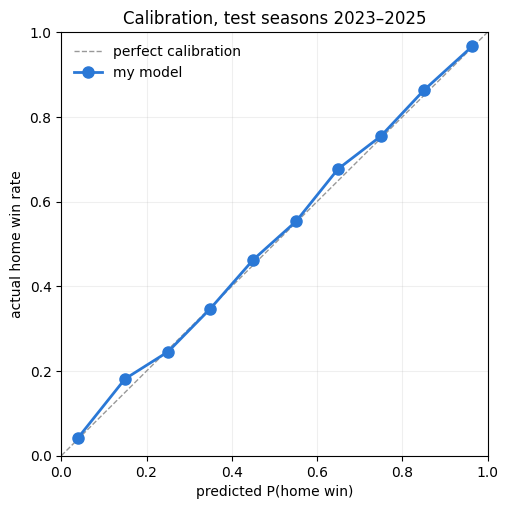

In [7]:
def calibration_table(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)   # prathi play ki bin number
    t = pd.DataFrame({"bin": idx, "p": p, "y": y}).groupby("bin").agg(
        predicted=("p", "mean"), actual=("y", "mean"), n=("y", "size"))
    return t

cal = calibration_table(y_test, p_test)
print(cal.round(3).to_string())

ece = np.sum(cal["n"] / cal["n"].sum() * (cal["predicted"] - cal["actual"]).abs())
print("\nECE (expected calibration error):", round(ece, 4))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="#999999", lw=1, ls="--", label="perfect calibration")
ax.plot(cal["predicted"], cal["actual"], color="#2a78d6", lw=2, marker="o", ms=8, label="my model")
ax.set_xlabel("predicted P(home win)")
ax.set_ylabel("actual home win rate")
ax.set_title("Calibration, test seasons 2023–2025")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(alpha=0.2); ax.legend(frameon=False)
plt.show()

In [8]:
mask = test["home_wp"].notna() & test["vegas_home_wp"].notna()
yt, pm = y_test[mask.to_numpy()], p_test[mask.to_numpy()]
p_nfl   = test.loc[mask, "home_wp"].to_numpy()
p_vegas = test.loc[mask, "vegas_home_wp"].to_numpy()

rows = []
for name, p in [("my model", pm), ("nflverse home_wp", p_nfl), ("nflverse vegas_home_wp", p_vegas)]:
    rows.append((name, log_loss(yt, p), brier(yt, p), roc_auc_score(yt, p)))
print("plays compared:", mask.sum())
print(pd.DataFrame(rows, columns=["model", "log_loss", "brier", "auc"]).round(4).to_string(index=False))

plays compared: 130811
                 model  log_loss  brier    auc
              my model    0.4541 0.1503 0.8635
      nflverse home_wp    0.4814 0.1627 0.8392
nflverse vegas_home_wp    0.4486 0.1486 0.8665
